# ResNet experts (Pool B)

Trains **one ResNet per expert** (real vs. that expert's fakes), calibrates it, and scores every image the
combiners use with every expert: the ResNet half of the score table. See `resnet/train.py` and `resnet/score.py`.

- **7 experts**, the same as the CLIP pool: ADM, BigGAN, glide, Midjourney, SD (SD 1.4 + 1.5 together), VQDM, wukong (`resnet/experts.py`).
- **Train:** ImageNet-pretrained ResNet, fine-tuned on the expert's own `expert_train` images (random 224 crop + flip).
  `expert_val` picks the best epoch (lowest loss, early stopping) and fits the temperature. No other pool is touched.
- **Score:** every image of `expert_val`, `meta_train`, `meta_val`, `test` (and any pool added later, e.g. a seen-test pool)
  → one raw logit per expert, saved as the feature set `resnet50_experts`. `load_scores()` returns calibrated
  probabilities `sigmoid(logit / T)`.

**Time on an M4 (16 GB), ResNet-50:** ~30 min per expert (≤ 8 epochs of 10k images at ~42 images/s), so ~2.5-3.5 h
for all 7, plus ~1.2 h scoring. `ARCH = "resnet18"` is ~2.5x faster.

**Safe to stop and rerun:** finished experts and scored images are saved and skipped.
Set `LIMIT = 100` first for a test run of the whole notebook (~10 min); it saves to separate folders.

In [2]:
import sys
sys.path.insert(0, "../..")  # repo root, so `common`, `data` and `resnet` are importable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from data import config
from resnet.experts import EXPERTS
from resnet.score import check, load_scores, score
from resnet.train import train_all

ARCH = "resnet50"  # "resnet18" if time is short
LIMIT = None  # e.g. 100 for a test run: 100 images per label and pool, saved separately
EPOCHS = 1 if LIMIT else 8
BATCH_SIZE = 64  # training; lower to 32 if you run out of memory
NUM_WORKERS = 4

print("dataset:", config.dataset_dir(), config.dataset_dir().exists())

dataset: /Users/tim/Developer/SC4001-Metalearners-Route-or-Pool/input/genimage_d8889a9c True


## 1 · Train and calibrate the 7 experts

In [1]:
infos = train_all(epochs=EPOCHS, limit=LIMIT, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, arch=ARCH)

NameError: name 'train_all' is not defined

### Training curves

Validation loss is on each expert's own `expert_val` images. `T` is the calibration temperature:
1 means the expert was already calibrated (or perfectly separated on validation), larger values soften it.

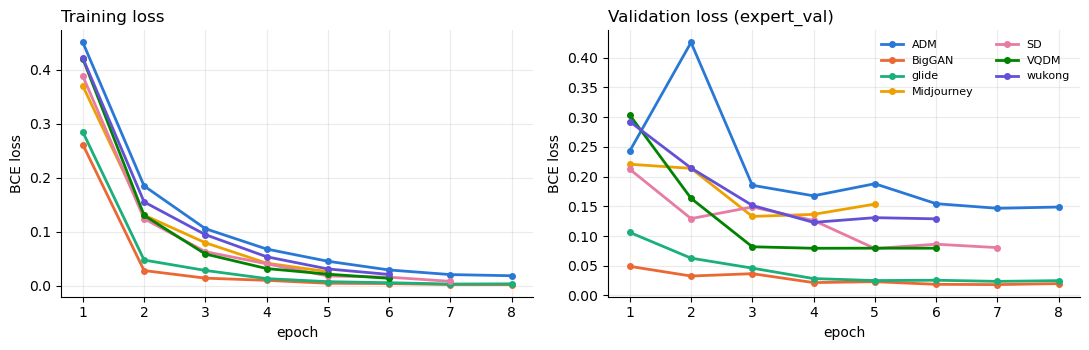

,expert,best epoch,epochs run,val auc,val acc,val loss,calibrated loss,T,minutes
0,ADM,7,8,0.9884,0.9490,0.1467,0.1357,1.4313,8.3667
1,BigGAN,7,8,0.9998,0.9945,0.0182,0.0172,1.2471,8.1333
2,glide,7,8,0.9997,0.9925,0.0237,0.0236,1.0588,8.1333
3,Midjourney,3,5,0.9898,0.9470,0.1330,0.1307,1.1882,5.1833
4,SD,5,7,0.9955,0.9755,0.0790,0.0764,1.2418,7.2833
5,VQDM,4,6,0.9966,0.9715,0.0794,0.0774,1.2085,6.3000
6,wukong,4,6,0.9917,0.9500,0.1230,0.1177,1.3002,6.5000


In [3]:
# Categorical slots in fixed order, one per expert.
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for color, (expert, info) in zip(COLORS, infos.items()):
    history = pd.DataFrame(info["history"])
    axes[0].plot(history.epoch, history.train_loss, color=color, lw=2, marker="o", ms=4, label=expert)
    axes[1].plot(history.epoch, history.val_loss, color=color, lw=2, marker="o", ms=4, label=expert)
for ax, title in zip(axes, ["Training loss", "Validation loss (expert_val)"]):
    ax.set_title(title, loc="left")
    ax.set_xlabel("epoch")
    ax.set_ylabel("BCE loss")
    ax.grid(alpha=0.25)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.spines[["top", "right"]].set_visible(False)
axes[1].legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

pd.DataFrame([{
    "expert": expert, "best epoch": info["best_epoch"], "epochs run": info["epochs_run"],
    "val auc": info["val"]["auc"], "val acc": info["val"]["acc"], "val loss": info["val"]["loss"],
    "calibrated loss": info["val_calibrated_loss"], "T": info["temperature"],
    "minutes": info["train_seconds"] / 60,
} for expert, info in infos.items()]).round(4)

## 2 · Score every image with every expert

In [4]:
score(limit=LIMIT, num_workers=NUM_WORKERS, arch=ARCH)
missing = check(limit=LIMIT, arch=ARCH)

[14:08:04] resnet18_experts: 96000 images in pools ['expert_val', 'meta_train', 'meta_val', 'test'], 0 done, 96000 to do
[14:08:06] 7 resnet18 experts on mps, batch size 128, 4 workers
[14:09:01] saved 5000 images to part_0000.npz
[14:09:13] 6400/96000 images (6.7%), elapsed 0h01m07s, ETA 0h15m44s, done at ~14:24
[14:09:48] saved 5000 images to part_0001.npz
[14:10:13] 12800/96000 images (13.3%), elapsed 0h02m07s, ETA 0h13m51s, done at ~14:24
[14:10:35] saved 5000 images to part_0002.npz
[14:11:14] 19200/96000 images (20.0%), elapsed 0h03m08s, ETA 0h12m34s, done at ~14:23
[14:11:23] saved 5000 images to part_0003.npz
[14:12:10] saved 5000 images to part_0004.npz
[14:12:14] 25600/96000 images (26.7%), elapsed 0h04m08s, ETA 0h11m24s, done at ~14:23
[14:12:57] saved 5000 images to part_0005.npz
[14:13:15] 32000/96000 images (33.3%), elapsed 0h05m09s, ETA 0h10m18s, done at ~14:23
[14:13:44] saved 5000 images to part_0006.npz
[14:14:16] 38400/96000 images (40.0%), elapsed 0h06m10s, ETA 0h09

## 3 · Using the scores in the combiners

Same shape as `data.features.load_features`: `X` has one column per expert in `EXPERTS` order,
`rows` the matching manifest rows. Drop the held-out expert's column per fold.

In [6]:
X, rows = load_scores(pool="meta_train", limit=LIMIT, arch=ARCH)  # calibrated=False for raw logits
print(X.shape, list(EXPERTS))
pd.DataFrame(X, columns=list(EXPERTS)).assign(generator=rows.generator.values, label=rows.label.values).head()

(32000, 7) ['ADM', 'BigGAN', 'glide', 'Midjourney', 'SD', 'VQDM', 'wukong']


,ADM,BigGAN,glide,Midjourney,SD,VQDM,wukong,generator,label
0,0.003774,0.000097,3.596333e-07,0.000984,0.000014,0.000009,0.000202,ADM,0
1,0.488061,0.314337,2.276122e-01,0.158687,0.095045,0.717597,0.056617,ADM,0
2,0.006015,0.000131,2.049815e-04,0.000033,0.000030,0.024783,0.000022,ADM,0
3,0.000172,0.000065,2.499749e-07,0.001043,0.005767,0.005294,0.003961,ADM,0
4,0.005255,0.001978,9.359410e-02,0.005698,0.000556,0.651929,0.016452,ADM,0
